In [2]:
import pandas as pd
import numpy as np

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


# **LOAD DATA**

In [3]:
df=pd.read_csv(r"C:\Users\P\Downloads\Customer Churn Prediction & Retention Prioritization\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# **BASIC INFORMATION**

In [4]:
print("\n=================shape===========")
print("shape:",df.shape)
print("\n=================columns===========")
print("columns:",df.columns.tolist())
print("\n=================info===========")
print(df.info())


=================shape===========
shape: (7043, 21)

=================columns===========
columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

=================info===========
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7

# **STATISTICAL SUMMARY**

In [5]:
print("\n========== STATISTICAL SUMMARY ==========") 
print(df.describe()) 


========== STATISTICAL SUMMARY ==========
       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000


# **MISSING VALUES AND DUPLICATES**

In [6]:
print("\n===============Missing Values==============")
print(df.isnull().sum())
print("\n==============Duplicate Values=============")
print(df.duplicated().sum())


===============Missing Values==============
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

==============Duplicate Values=============
0


# **Data Cleaning**

In [7]:
(df['TotalCharges'] == " ").sum()
df['TotalCharges'] = df['TotalCharges'].replace(" ",np.nan)
df['TotalCharges'] = df['TotalCharges'].astype(float)

In [35]:
churn_flag = (df['Churn'] == 'Yes').astype(int)  
overall_rate = churn_flag.mean() * 100
df.shape

(7043, 20)

# **FEATURE SELECTION/SEPRATION**

In [8]:
# drop Customer ID column 
df.drop(columns=['customerID'],inplace=True)

In [9]:
Numerical_cols=df.select_dtypes(include=['int','float'])
Categorical_cols=df.select_dtypes(include=['object'])

C:\Users\P\AppData\Local\Temp\ipykernel_20540\284461891.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Categorical_cols=df.select_dtypes(include=['object'])


# **Univariate Analysis**

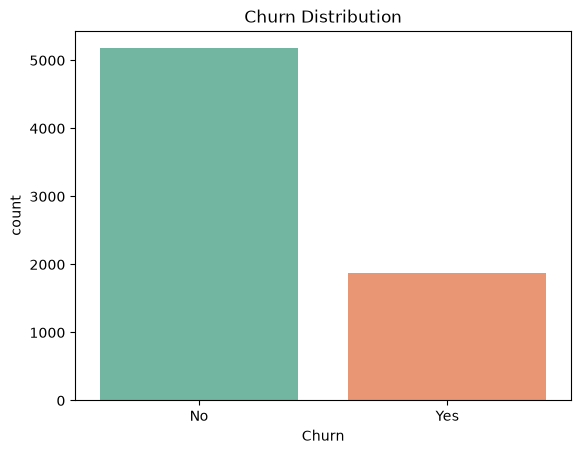

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [10]:
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)
plt.title("Churn Distribution")
plt.show()

print((df['Churn'].value_counts(normalize=True) * 100).round(2))

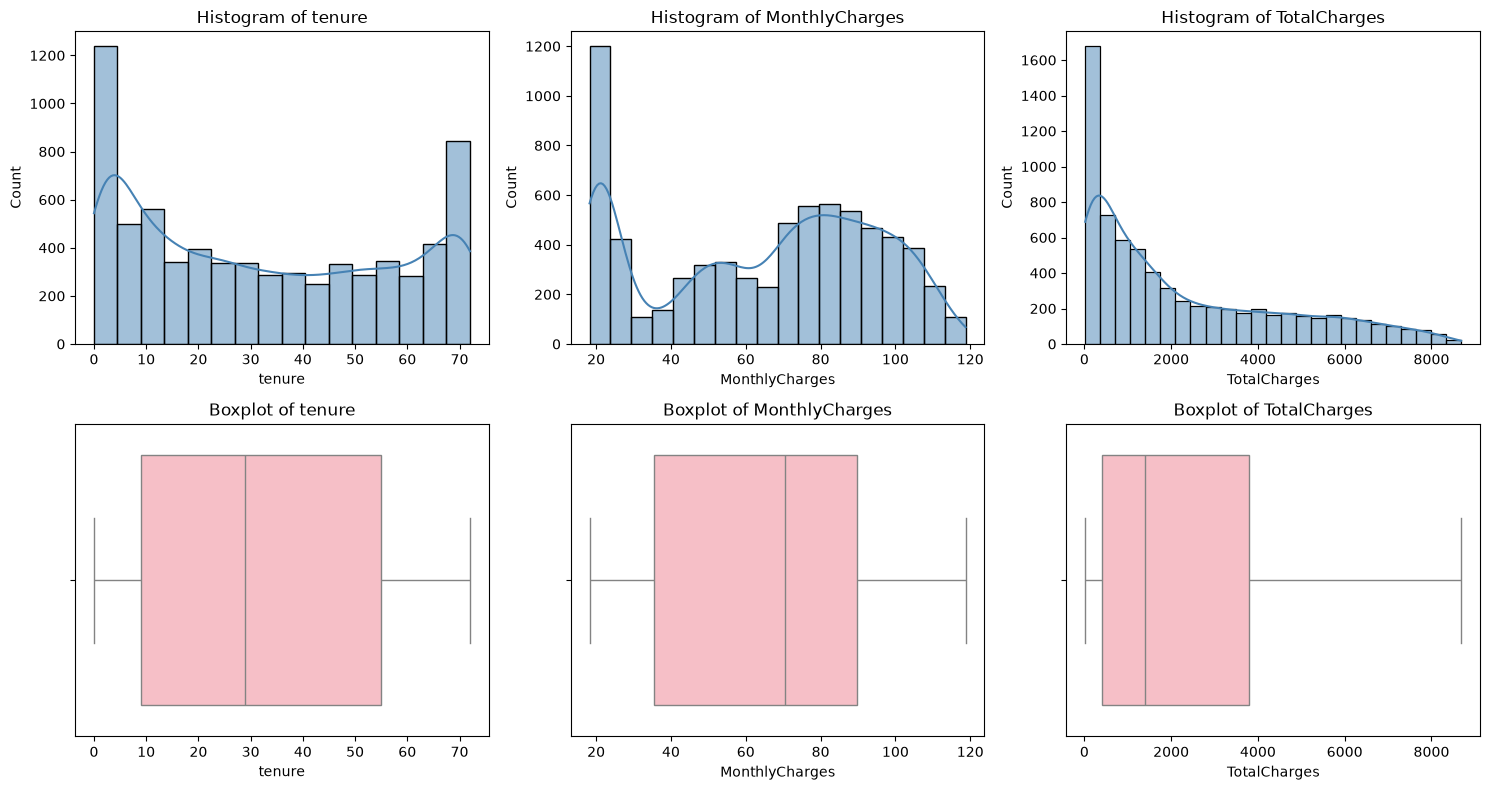

In [31]:
cols = ['tenure', 'MonthlyCharges', 'TotalCharges']  

plt.figure(figsize=(15, 8))

for i, col in enumerate(cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col].dropna(), kde=True, color='steelblue')
    plt.title(f"Histogram of {col}")

    plt.subplot(2, 3, i + 3)
    sns.boxplot(x=df[col].dropna(), color='lightpink')
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


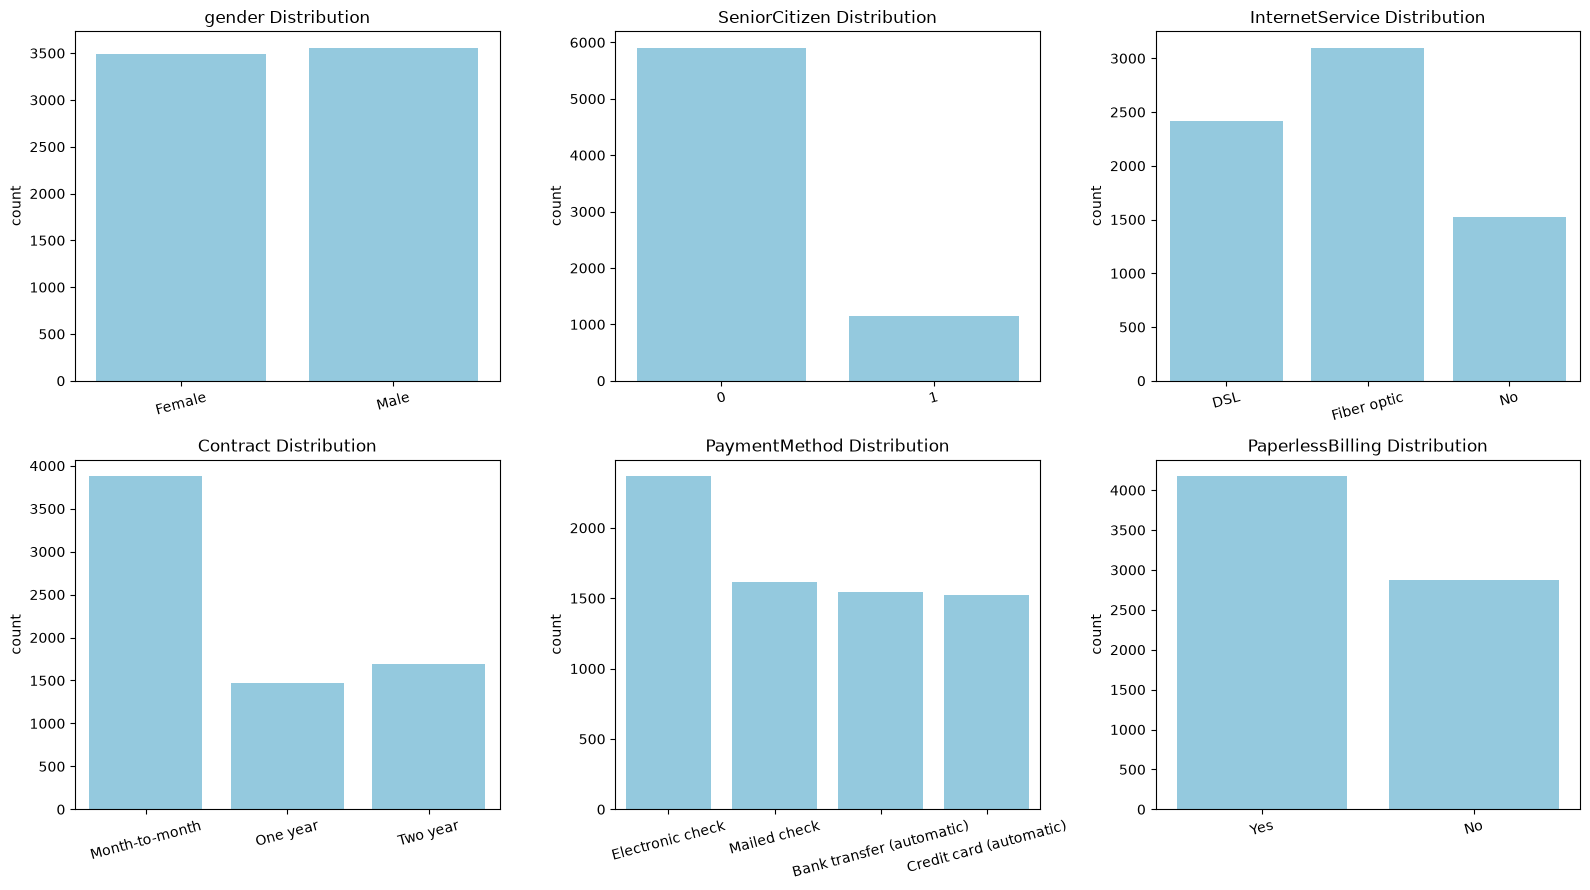

In [32]:
important_cat = ['gender', 'SeniorCitizen', 'InternetService',
                 'Contract', 'PaymentMethod', 'PaperlessBilling']

plt.figure(figsize=(16, 9))
for i, col in enumerate(important_cat, 1):
    plt.subplot(2, 3, i)
    sns.countplot(data=df, x=col, color='skyblue')
    plt.title(f"{col} Distribution")
    plt.xlabel('')
    plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Univariate findings**
- About 1 in 4 customers churned (26.5%), so the data is imbalanced.
- `tenure` has two peaks: many new customers and many long-term customers.
- `TotalCharges` is right-skewed (0.96): most customers have small totals. No column has outliers.
- 55% of customers are on **Month-to-month** contracts, 44% use **Fiber optic**, and **Electronic check** is the most common payment method (33.6%).
- Gender is balanced (50.5% male) and only 16.2% are senior citizens.

# **Bivariate Analysis**

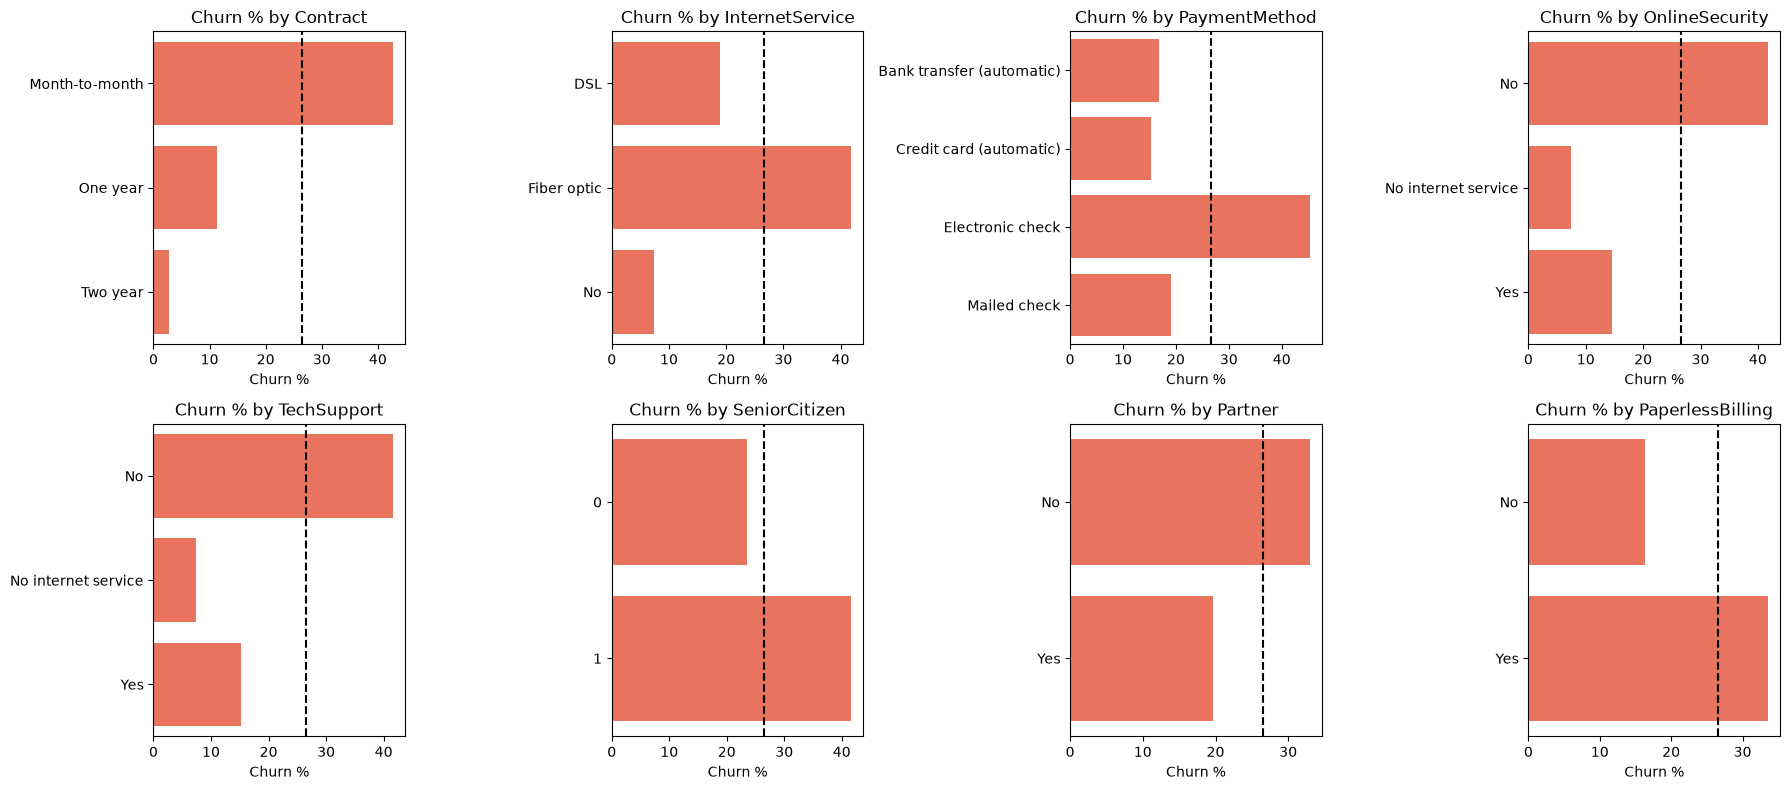

In [36]:
cat_vs_churn = ['Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity',
                'TechSupport', 'SeniorCitizen', 'Partner', 'PaperlessBilling']

plt.figure(figsize=(18, 8))
for i, col in enumerate(cat_vs_churn, 1):
    plt.subplot(2, 4, i)
    rate = churn_flag.groupby(df[col]).mean() * 100
    sns.barplot(x=rate.values, y=rate.index.astype(str), color='tomato')
    plt.axvline(overall_rate, color='black', linestyle='--')
    plt.title(f"Churn % by {col}")
    plt.xlabel('Churn %')
    plt.ylabel('')
plt.tight_layout()
plt.show()

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       2555.34
Yes     17.98           74.44       1531.80


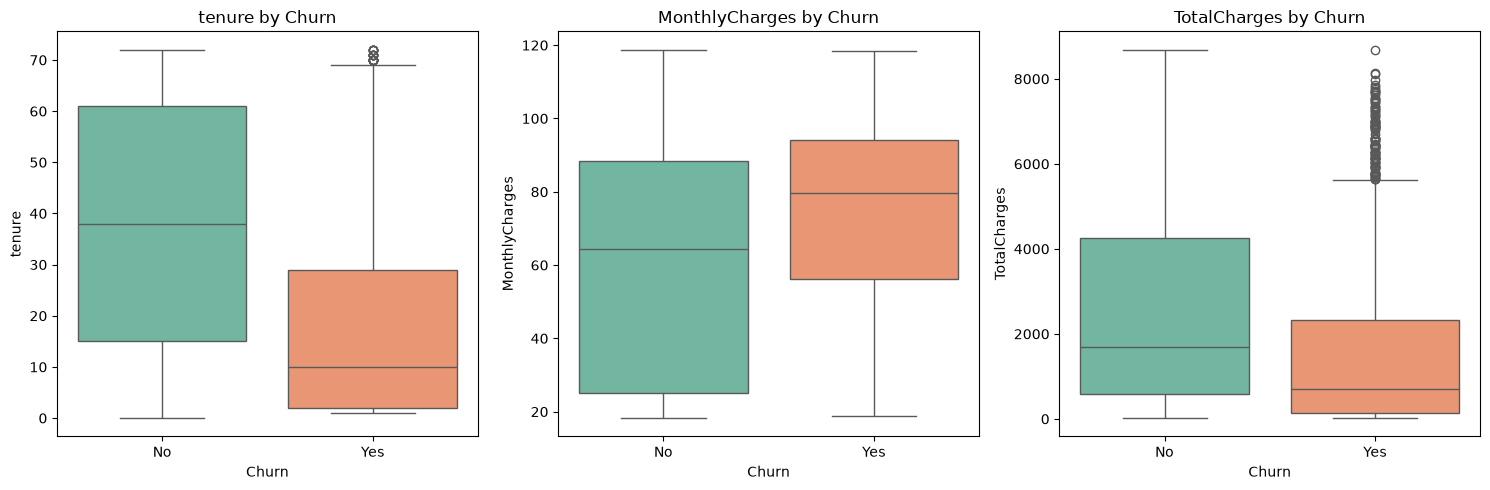

In [37]:
print(df.groupby('Churn')[cols].mean().round(2))

plt.figure(figsize=(15, 5))
for i, col in enumerate(cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(data=df, x='Churn', y=col, hue='Churn', palette='Set2', legend=False)
    plt.title(f"{col} by Churn")
plt.tight_layout()
plt.show()

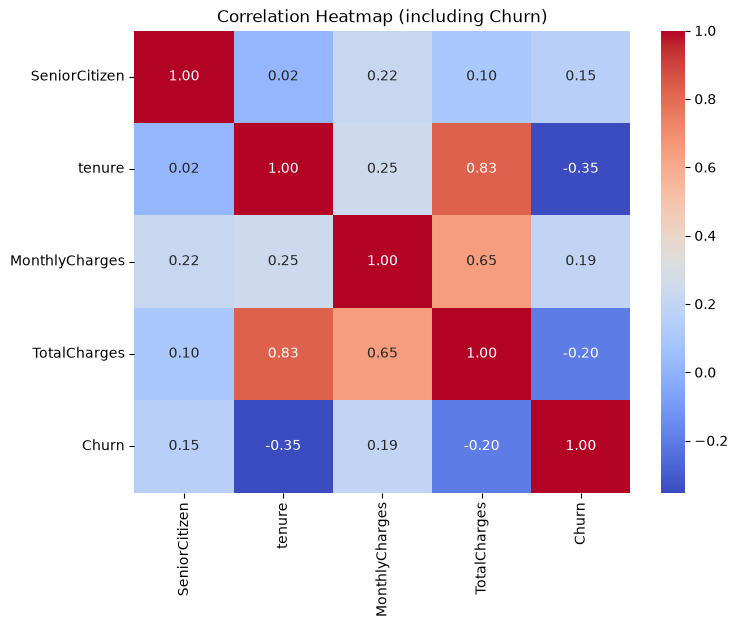

In [38]:
corr_data = df[['SeniorCitizen'] + cols].copy()
corr_data['Churn'] = churn_flag

plt.figure(figsize=(8, 6))
sns.heatmap(corr_data.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlation Heatmap (including Churn)")
plt.show()

**Bivariate findings**
- **Contract** is the strongest driver: Month-to-month 42.7% churn, One year 11.3%, Two year 2.8%.
- **Electronic check** users churn the most (45.3%); automatic payments are the lowest (~15-17%).
- **Fiber optic** churns at 41.9% vs DSL 19.0%.
- Customers **without OnlineSecurity or TechSupport** churn about 3x more (~42% vs ~15%).
- Senior citizens (41.7% vs 23.6%), customers with no partner (33.0% vs 19.7%) and paperless billing (33.6% vs 16.3%) churn more.
- Churned customers have a much lower average tenure (18 vs 37.6 months) and pay more per month (74.4 vs 61.3).
- Correlation with Churn: `tenure` -0.35, `TotalCharges` -0.20, `MonthlyCharges` +0.19, `SeniorCitizen` +0.15.

# **Multivariate Analysis**

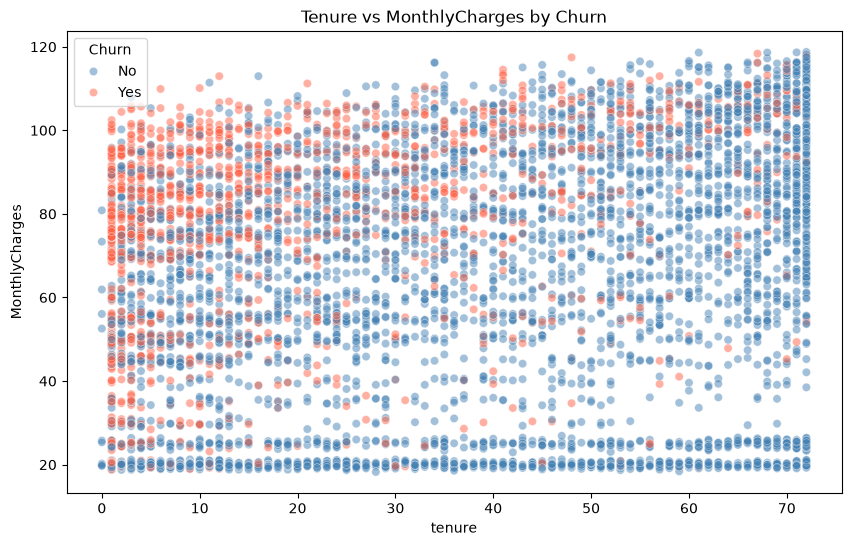

In [39]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='Churn',
                palette={'No': 'steelblue', 'Yes': 'tomato'}, alpha=0.5)
plt.title("Tenure vs MonthlyCharges by Churn")
plt.show()

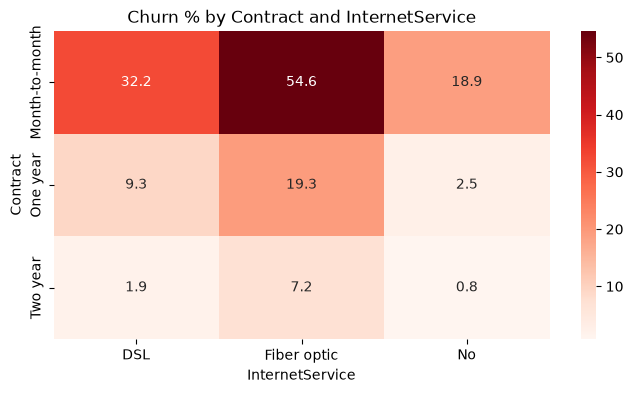

In [40]:
churn_pivot = pd.crosstab(df['Contract'], df['InternetService'],
                          values=churn_flag, aggfunc='mean') * 100

plt.figure(figsize=(8, 4))
sns.heatmap(churn_pivot, annot=True, fmt='.1f', cmap='Reds')
plt.title("Churn % by Contract and InternetService")
plt.show()

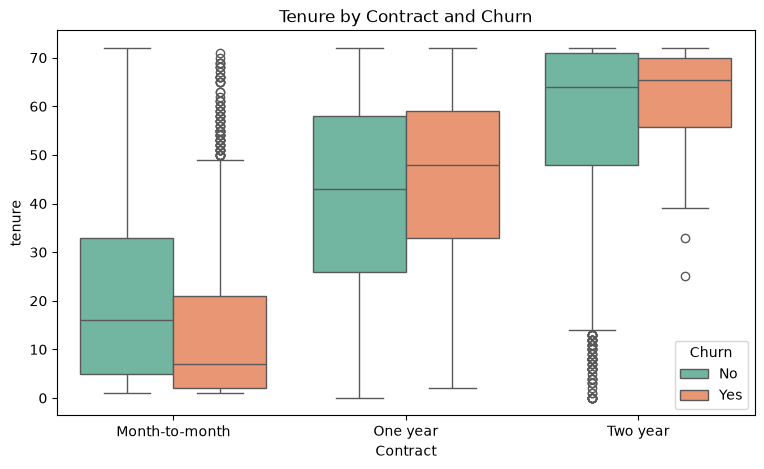

In [41]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Contract', y='tenure', hue='Churn', palette='Set2')
plt.title("Tenure by Contract and Churn")
plt.show()

**Multivariate findings**
- Churned customers sit mostly in the **low tenure + high MonthlyCharges** area.
- The riskiest group is **Month-to-month + Fiber optic** (54.6% churn). Two-year contracts are below 8% for every internet type.
- Customers with tenure up to 12 months and MonthlyCharges above 70 churn at about 68%, vs about 21% for everyone else.
- On Month-to-month contracts, churners leave early (median tenure 7 months vs 16 for those who stay).

In [43]:
df.to_csv(r"C:\Users\P\Downloads\Customer Churn Prediction & Retention Prioritization\data\processed\cleaned_telco_churn.csv",index=False)